Group 2: Anthony Navarro, Anusuya Roysarkar, Lauren Yoder

**Problem:** Optimize gate utilization for United Airlines at Denver International Airport (DEN) by assigning United departures to gates over the July 2025 schedule

**Dataset:** Bureau of Transportation Statistics (BTS) Trans Stats > Detailed Statistics > Departures https://www.transtats.bts.gov/ONTIME/Departures.aspx
>	Fields: FlightDate, Carrier, Origin, Dest, CRSDepTime, CRSArrTime, CRSElapsedTime

**Objective Function:** Minimize number of gates used for departing flights during the month of July

**Decision Variables:**
> Number of Gates Used, K (Integer)

**Constraints:**
- K ≥ occ[t] (for minutes with positive occupancy)
- K > 0


**Assumptions:**
- United has about 90 Gates at DEN
- A gate should be reserved for a flight for 45 minutes prior to its scheduled departure and 15 minutes following that time


In [ ]:
pip install gurobipy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 104.6 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from gurobipy import Model, GRB, quicksum

In [ ]:
# Parameters
DATA_PATH = "Detailed_Statistics_Departures.csv"

# time buffer assumptions (minutes)
BUFFER_BEFORE = 45   # gate occupied 45 min before scheduled departure
BUFFER_AFTER  = 15   # gate occupied 15 min after scheduled departure

# number of potential United gates at DEN
MAX_GATES = 95


#Load & Prep Data
flights = pd.read_csv(DATA_PATH, skiprows=7)

# Keep only fields needed for this model
flights = flights[[
    "Carrier Code",
    "Date (MM/DD/YYYY)",
    "Flight Number",
    "Tail Number",
    "Destination Airport",
    "Scheduled departure time",
]]

# Create full departure datetime from date + scheduled time
flights["dep_dt"] = pd.to_datetime(
    flights["Date (MM/DD/YYYY)"] + " " + flights["Scheduled departure time"]
)

# Pure date for grouping by calendar day
flights["day"] = flights["dep_dt"].dt.date



In [ ]:
#Function for minimum gates for one day
def compute_min_gates_for_day(day_df, buffer_before=45, buffer_after=15):
    """
    Given all flights for a single calendar day in day_df (with column 'dep_dt'),
    compute the minimum number of identical gates required using a tiny Gurobi model:
        min K  s.t.  K >= #flights occupying each minute of the day.
    """

    if day_df.empty:
        return 0

    # Midnight of this specific day
    day_start = pd.Timestamp(day_df["dep_dt"].iloc[0].date())

    # Minutes since midnight for each departure
    t_dep_min = (day_df["dep_dt"] - day_start).dt.total_seconds() / 60.0

    # Gate-occupancy interval per flight: [start_min, end_min)
    start_min = (t_dep_min - buffer_before).astype(int)
    end_min   = (t_dep_min + buffer_after).astype(int)

    # Restrict to the 0..1439 minutes of that calendar day
    T = 24 * 60
    start_min[start_min < 0] = 0
    end_min[end_min > T] = T

    # Build occupancy array: occ[t] = how many flights use a gate at minute t
    occ = [0] * T
    for s, e in zip(start_min, end_min):
        for t in range(s, e):   # interval [s, e)
            occ[t] += 1

    #Gurobi model:
    #subject to K >= occ[t] for all minutes with occ[t] > 0
    m = Model("MinGates_OneDay")
    m.Params.OutputFlag = 0  # silence solver chatter

    K = m.addVar(vtype=GRB.INTEGER, lb=0, name="K")

    for t in range(T):
        if occ[t] > 0:
            m.addConstr(K >= occ[t], name=f"time_{t}")

    m.setObjective(K, GRB.MINIMIZE)
    m.optimize()

    if m.Status == GRB.OPTIMAL:
        return int(K.X)
    else:
        print("Warning: Gurobi status", m.Status, "- using max(occ) instead.")
        return max(occ)


#Loop over all days in July
results = []

unique_days = sorted(flights["day"].unique())
print("Days in data:", unique_days)

for d in unique_days:
    day_df = flights[flights["day"] == d].copy()
    num_flights = len(day_df)

    min_gates = compute_min_gates_for_day(
        day_df,
        buffer_before=BUFFER_BEFORE,
        buffer_after=BUFFER_AFTER,
    )

    results.append({
        "Date": d,
        "NumFlights": num_flights,
        "MinGates": min_gates})


#Display Results
res_df = pd.DataFrame(results).sort_values("Date")
print("\nMinimum gates required per day:")
print(res_df)

res_df.to_csv("min_gates_per_day.csv", index=False)

Days in data: [datetime.date(2025, 7, 1), datetime.date(2025, 7, 2), datetime.date(2025, 7, 3), datetime.date(2025, 7, 4), datetime.date(2025, 7, 5), datetime.date(2025, 7, 6), datetime.date(2025, 7, 7), datetime.date(2025, 7, 8), datetime.date(2025, 7, 9), datetime.date(2025, 7, 10), datetime.date(2025, 7, 11), datetime.date(2025, 7, 12), datetime.date(2025, 7, 13), datetime.date(2025, 7, 14), datetime.date(2025, 7, 15), datetime.date(2025, 7, 16), datetime.date(2025, 7, 17), datetime.date(2025, 7, 18), datetime.date(2025, 7, 19), datetime.date(2025, 7, 20), datetime.date(2025, 7, 21), datetime.date(2025, 7, 22), datetime.date(2025, 7, 23), datetime.date(2025, 7, 24), datetime.date(2025, 7, 25), datetime.date(2025, 7, 26), datetime.date(2025, 7, 27), datetime.date(2025, 7, 28), datetime.date(2025, 7, 29), datetime.date(2025, 7, 30), datetime.date(2025, 7, 31)]
Restricted license - for non-production use only - expires 2027-11-29

Minimum gates required per day:
          Date  NumFlig

We have our minimums, but we want to look at it graphically

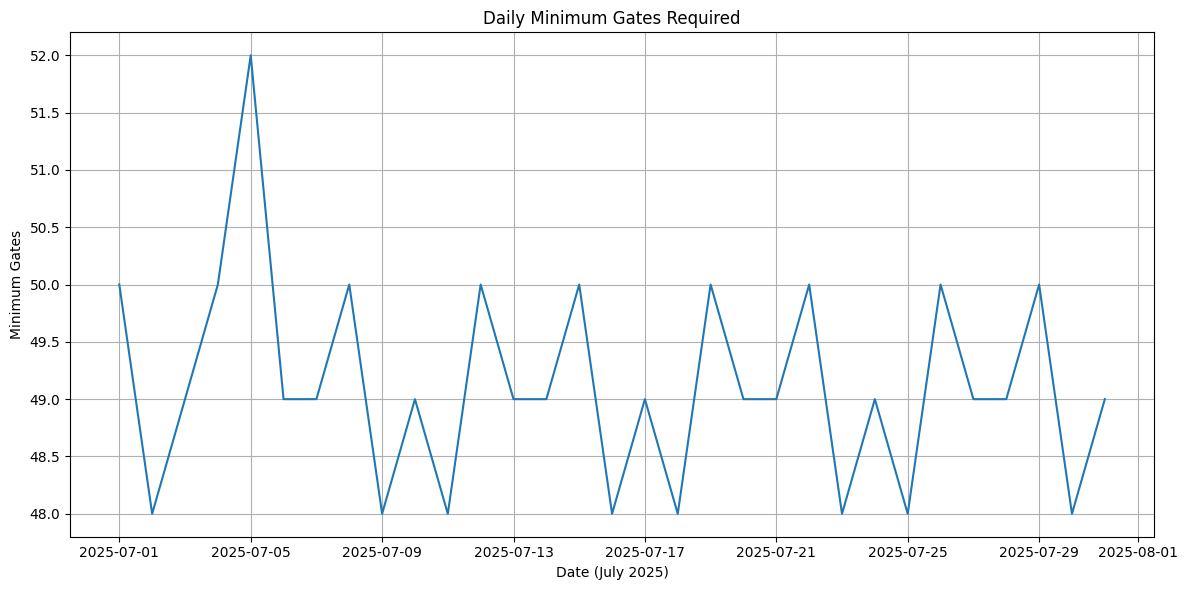

In [ ]:
#Visualize Results
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure 'Date' column is in datetime format for plotting
res_df['Date'] = pd.to_datetime(res_df['Date'])

plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='MinGates', data=res_df)
plt.title('Daily Minimum Gates Required')
plt.xlabel('Date (July 2025)')
plt.ylabel('Minimum Gates')
plt.grid(True)
plt.tight_layout()
plt.show()

We noticed an unexpectec relatioship between the number of flights per day and the minimum required gates per day that we wanted to visualize

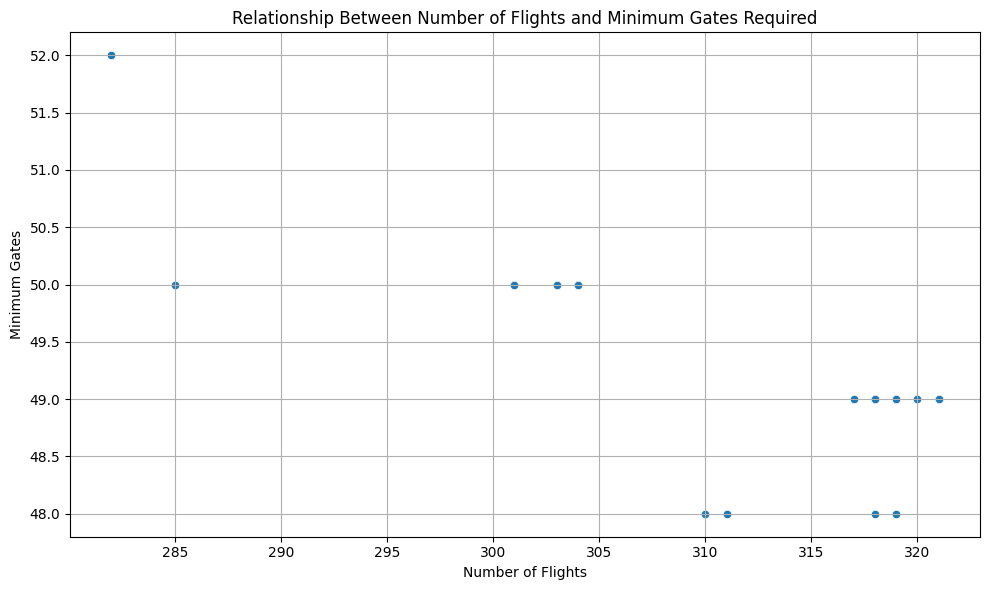

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='NumFlights', y='MinGates', data=res_df)
plt.title('Relationship Between Number of Flights and Minimum Gates Required')
plt.xlabel('Number of Flights')
plt.ylabel('Minimum Gates')
plt.grid(True)
plt.tight_layout()
plt.show()

We noticed a trend over weekdays, we then wanted to visualize this relationship

In [ ]:
# Ensure 'Date' is datetime if not already
res_df['Date'] = pd.to_datetime(res_df['Date'])

# Extract weekday name
res_df['Weekday'] = res_df['Date'].dt.day_name()

# Calculate average flights and min gates per weekday
weekday_summary = res_df.groupby('Weekday')[['NumFlights', 'MinGates']].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])

print("\nAverage Flights and Minimum Gates per Weekday:")
print(weekday_summary)


Average Flights and Minimum Gates per Weekday:
           NumFlights  MinGates
Weekday                        
Monday         318.75      49.0
Tuesday        303.60      50.0
Wednesday      310.60      48.0
Thursday       320.60      49.0
Friday         310.25      48.5
Saturday       296.25      50.5
Sunday         317.75      49.0


/tmp/ipython-input-3196063780.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekday_summary.index, y='NumFlights', data=weekday_summary, ax=axes[0], palette='viridis')
/tmp/ipython-input-3196063780.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekday_summary.index, y='MinGates', data=weekday_summary, ax=axes[1], palette='plasma')


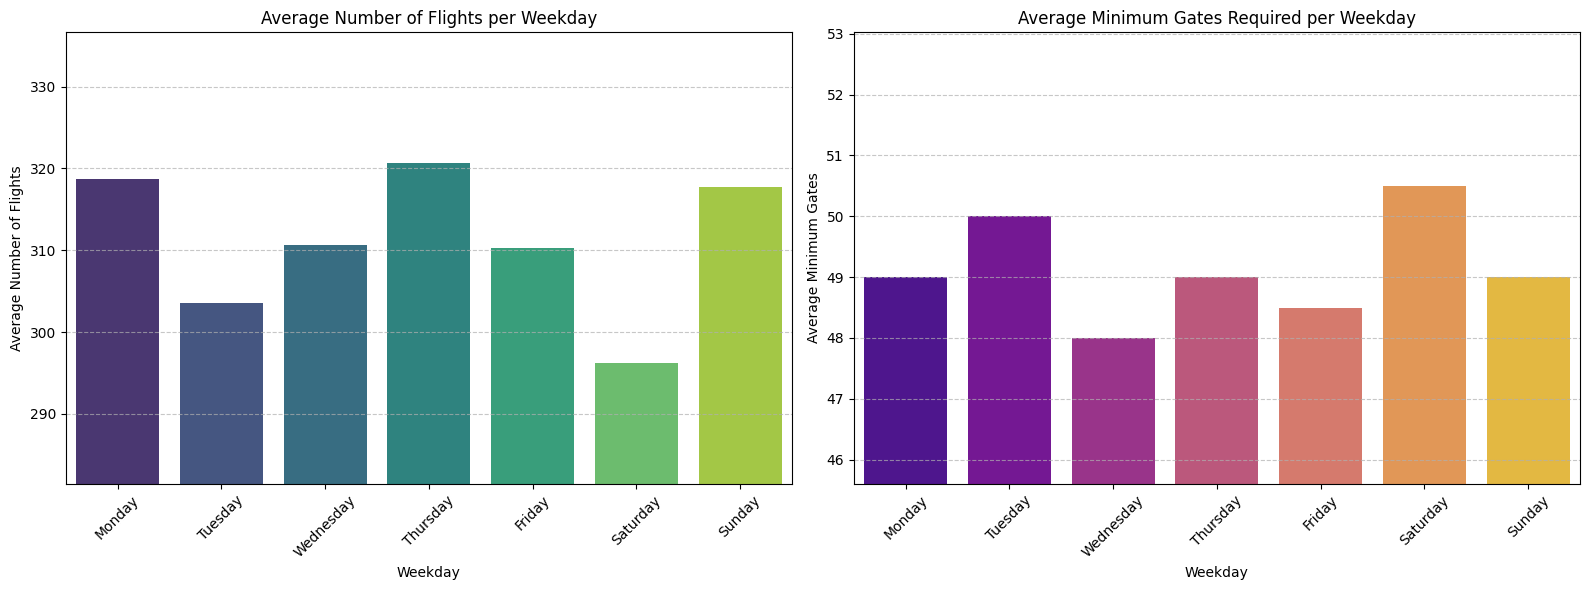

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

# Plot Average NumFlights per Weekday
sns.barplot(x=weekday_summary.index, y='NumFlights', data=weekday_summary, ax=axes[0], palette='viridis')
axes[0].set_title('Average Number of Flights per Weekday')
axes[0].set_xlabel('Weekday')
axes[0].set_ylabel('Average Number of Flights')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
# Adjust y-axis limits for NumFlights to make differences more obvious
min_flights = weekday_summary['NumFlights'].min()
max_flights = weekday_summary['NumFlights'].max()
axes[0].set_ylim(min_flights * 0.95, max_flights * 1.05) # Set limits slightly wider than the data range

# Plot Average MinGates per Weekday
sns.barplot(x=weekday_summary.index, y='MinGates', data=weekday_summary, ax=axes[1], palette='plasma')
axes[1].set_title('Average Minimum Gates Required per Weekday')
axes[1].set_xlabel('Weekday')
axes[1].set_ylabel('Average Minimum Gates')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
# Adjust y-axis limits for MinGates to make differences more obvious
min_gates = weekday_summary['MinGates'].min()
max_gates = weekday_summary['MinGates'].max()
axes[1].set_ylim(min_gates * 0.95, max_gates * 1.05) # Set limits slightly wider than the data range

plt.tight_layout()
plt.show()

# Sensitivity Analysis
Perform a sensitivity analysis on the `BUFFER_BEFORE` and `BUFFER_AFTER` parameters for gate occupancy using the `Detailed_Statistics_Departures.csv` dataset. Define a range of values for both parameters, recompute the minimum daily gates required for all days for each combination, and visualize the maximum gates required as a function of `BUFFER_BEFORE` and `BUFFER_AFTER` to understand their impact on gate utilization.

In [ ]:
buffer_before_values = [45, 60, 90]
buffer_after_values = [15, 30, 45]

print(f"BUFFER_BEFORE values for sensitivity analysis: {buffer_before_values}")
print(f"BUFFER_AFTER values for sensitivity analysis: {buffer_after_values}")

BUFFER_BEFORE values for sensitivity analysis: [45, 60, 90]
BUFFER_AFTER values for sensitivity analysis: [15, 30, 45]


In [ ]:
sensitivity_results = []

for b_before in buffer_before_values:
    for b_after in buffer_after_values:
        daily_min_gates = []
        for d in unique_days:
            day_df = flights[flights["day"] == d].copy()
            min_gates = compute_min_gates_for_day(
                day_df,
                buffer_before=b_before,
                buffer_after=b_after,
            )
            daily_min_gates.append(min_gates)

        max_daily_gates = max(daily_min_gates)
        sensitivity_results.append({
            "BUFFER_BEFORE": b_before,
            "BUFFER_AFTER": b_after,
            "Max_Daily_Gates": max_daily_gates
        })

sensitivity_df = pd.DataFrame(sensitivity_results)
print("\nSensitivity Analysis Results:")
print(sensitivity_df)


Sensitivity Analysis Results:
   BUFFER_BEFORE  BUFFER_AFTER  Max_Daily_Gates
0             45            15               52
1             45            30               53
2             45            45               53
3             60            15               53
4             60            30               53
5             60            45               69
6             90            15               69
7             90            30               84
8             90            45               90


We wanted to visualize this sensitivity analysis as a heatmap



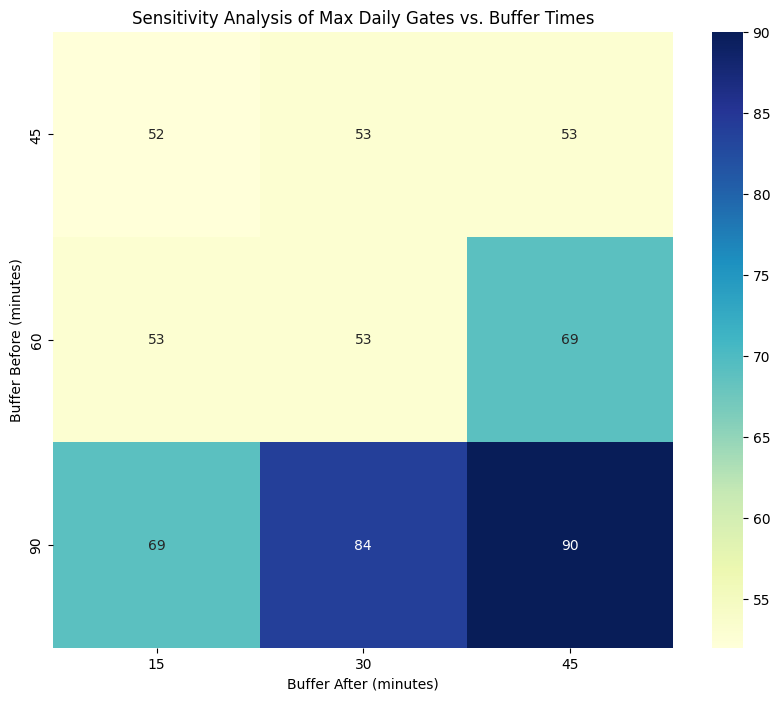

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot the DataFrame to create a matrix for the heatmap
heatmap_data = sensitivity_df.pivot(index='BUFFER_BEFORE', columns='BUFFER_AFTER', values='Max_Daily_Gates')

# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlGnBu")

# Add title and labels
plt.title('Sensitivity Analysis of Max Daily Gates vs. Buffer Times')
plt.xlabel('Buffer After (minutes)')
plt.ylabel('Buffer Before (minutes)')
plt.show()